# Qualifying: driver strengths by corner type

Which drivers are strongest on the straights, in fast corners or in slow corners, and can that predict who will be quick on a circuit they haven't raced on yet?

**Method**
1. Split every lap into 25 equal-length mini-sectors.
2. Classify each mini-sector of the pole lap as a straight or a high-, medium- or low-speed corner, using track curvature and speed.
3. For each driver's best qualifying lap, compare the time in every mini-sector with the fastest time anyone set there. Per sector type, this gives a rating where **100 % = fastest in every mini-sector of that type**.
4. Describe each circuit by the share of the lap it spends in each sector type, and combine that with the driver ratings to predict qualifying pace on a new circuit.

**Data:** 2026 qualifying sessions of Australia, China, Japan and Miami, loaded with [FastF1](https://github.com/theOehrly/Fast-F1).

## 1. Setup

In [1]:
%pip install -q fastf1

import logging
import tempfile
import warnings

import fastf1
import fastf1.plotting
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logging.getLogger('fastf1').setLevel(logging.WARNING)   # keep warnings: failed downloads show up here
warnings.filterwarnings('ignore')

# No local cache: the data is downloaded on every run and nothing is kept on disk.
# FastF1 needs some cache folder configured, otherwise it creates its default one (~1 GB) and
# prints its full path, so it gets an empty temporary folder and the cache is switched off.
fastf1.Cache.enable_cache(tempfile.mkdtemp())
fastf1.Cache.set_disabled()

N_SECTORS = 25
SECTOR_TYPES = ['Straight', 'High-Speed Corner', 'Medium-Speed Corner', 'Low-Speed Corner']
TRAIN_CIRCUITS = ['Australia', 'China', 'Japan', 'Miami']   # 2026 qualifying sessions

Note: you may need to restart the kernel to use updated packages.


## 2. Mini-sectors

Every lap is split into `N_SECTORS` pieces of equal length. For the times to be comparable, a boundary has to sit at **the same physical spot on the track** for every driver.

- **Aligned to the track.** FastF1's `Distance` is integrated from the speed channel. It is smooth, but it can drift: a glitch in the speed data, or a lap whose telemetry starts slightly before or after the line, shifts all of that driver's boundaries, and his "sector 5" ends up on a different piece of track. Taking the fastest time per sector then mixes pieces of different lengths, and the "ideal" lap comes out far too fast. That is why China and Japan first came out at 116–123 % for every driver. The X/Y position doesn't drift, but it is noisy and has gaps, so using it point by point isn't accurate enough either. The two are therefore combined: every point is matched by X/Y to the pole lap's racing line, and the median offset between that match and the driver's own distance, taken over short pieces of track, corrects the drift. Points far from the track (gaps in the position data) are ignored.
- **Interpolated crossing times.** Telemetry comes in roughly every 0.1–0.25 s, while a mini-sector lasts 2–3 s. The moment each boundary is crossed is interpolated rather than read off the nearest sample. Sectors outside a lap's telemetry are left empty instead of being guessed.

In [2]:
def lap_telemetry(lap):
    # Distance and RelativeDistance recomputed from the start of this lap
    return lap.get_telemetry().add_distance().add_relative_distance()


def sector_index(rel_distance, n=N_SECTORS):
    # Mini-sector number (0 … n-1) of every telemetry point
    return np.minimum((np.asarray(rel_distance) * n).astype(int), n - 1)


def reference_track(pole_tel, step=1.0):
    # Pole lap racing line resampled every metre, for fast nearest-point lookups
    d = pole_tel['Distance'].to_numpy()
    grid = np.linspace(0, d[-1], int(d[-1] / step) + 1)        # includes the end of the lap
    xy = np.c_[np.interp(grid, d, pole_tel['X']), np.interp(grid, d, pole_tel['Y'])]
    return {'tree': cKDTree(xy), 'rel': grid / d[-1]}


def track_position(tel, ref, n_bins=40, max_dist=15.0, k=40, window=0.15):
    # Position of every telemetry point on the reference lap (0 → 1).
    own = tel['RelativeDistance'].to_numpy()            # smooth, but may drift
    xy = np.nan_to_num(tel[['X', 'Y']].to_numpy(dtype=float), nan=1e9)

    # 1. Match each point by X/Y to the racing line. Among the k nearest reference points, take the
    #    closest one within `window` of the point's own distance, so crossings (Suzuka) aren't confused.
    dist, idx = ref['tree'].query(xy, k=k)
    cand = ref['rel'][idx]
    gap = np.abs(cand - own[:, None])
    gap = np.minimum(gap, 1 - gap)                      # the lap is a loop
    ok = gap < window
    rows, first = np.arange(len(own)), ok.argmax(axis=1)
    match, match_dist = cand[rows, first], dist[rows, first]
    # Points just before / after the line match the other end of the lap: unwrap them
    match = np.where((own < 0.5) & (match - own > 0.5), match - 1, match)
    match = np.where((own > 0.5) & (own - match > 0.5), match + 1, match)
    good = ok.any(axis=1) & (match_dist < max_dist)    # drop points far from the track (data gaps)

    # 2. Drift of the distance channel = median offset to the X/Y match over short pieces of track
    #    (~2.5 % of the lap each). The median ignores the noise in X/Y.
    bins = np.minimum((own * n_bins).astype(int), n_bins - 1)
    centers, offsets = [], []
    for b in range(n_bins):
        m = good & (bins == b)
        if m.sum() >= 3:
            centers.append(own[m].mean())
            offsets.append(np.median(match[m] - own[m]))
    pos = own + (np.interp(own, centers, offsets) if centers else 0)
    pos = np.maximum.accumulate(pos)                    # a car only moves forward

    # Lap telemetry is cut at the timing line: snap ends that are within 1 % of it onto the line
    if 0 < pos[0] < 0.01:
        pos[0] = 0.0
    if 0.99 < pos[-1] < 1:
        pos[-1] = 1.0
    return pos


def sector_times(tel, ref, n=N_SECTORS):
    pos = track_position(tel, ref)
    t = tel['Time'].dt.total_seconds().to_numpy()
    edges = np.linspace(0, 1, n + 1)
    crossing = np.interp(edges, pos, t)                              # time at each boundary
    crossing[(edges < pos[0]) | (edges > pos[-1])] = np.nan          # boundary not covered by this lap
    return pd.Series(np.diff(crossing), index=pd.RangeIndex(n, name='sector_id'), name='sector_time')


def add_curvature(tel):
    # Menger curvature (1 / radius) of the circle through each point and its two neighbours
    x, y = tel['X'].to_numpy(dtype=float), tel['Y'].to_numpy(dtype=float)
    ax, ay, bx, by, cx, cy = x[:-2], y[:-2], x[1:-1], y[1:-1], x[2:], y[2:]
    ab, bc, ac = np.hypot(bx - ax, by - ay), np.hypot(cx - bx, cy - by), np.hypot(cx - ax, cy - ay)
    cross = np.abs((bx - ax) * (cy - ay) - (cx - ax) * (by - ay))   # = 2 x triangle area
    denom = ab * bc * ac
    curv = np.zeros(len(tel))
    curv[1:-1] = np.divide(2 * cross, denom, out=np.zeros_like(denom), where=denom > 1e-6)
    return tel.assign(Curvature=curv)


def classify_sectors(tel, n=N_SECTORS):
    # Label each mini-sector of the reference lap from its curvature and its speed relative to top speed
    tel = add_curvature(tel)
    stats = tel.groupby(sector_index(tel['RelativeDistance'], n)).agg(
        speed_mean=('Speed', 'mean'), curv_mean=('Curvature', 'mean'))
    stats.index.name = 'sector_id'
    speed_ratio = stats['speed_mean'] / tel['Speed'].max()
    curv_ratio = stats['curv_mean'] / tel['Curvature'].quantile(0.95)
    stats['type'] = np.select(
        [curv_ratio <= 0.15, speed_ratio >= 0.70, speed_ratio >= 0.40],
        ['Straight', 'High-Speed Corner', 'Medium-Speed Corner'],
        default='Low-Speed Corner')
    return stats

## 3. Loading a circuit

Each session is loaded **once**. The pole lap defines the racing line, the sector types and the circuit profile (the share of the lap spent in each type). Every driver's best lap is then split into mini-sectors along that line.

In [3]:
def load_circuit(year, gp, with_drivers=True, n=N_SECTORS):
    session = fastf1.get_session(year, gp, 'Q')
    session.load(laps=True, telemetry=True, weather=False, messages=False)

    pole_lap = session.laps.pick_fastest()
    pole_tel = lap_telemetry(pole_lap)
    ref = reference_track(pole_tel)
    sectors = classify_sectors(pole_tel, n)
    sectors['sector_time'] = sector_times(pole_tel, ref, n)

    # Circuit profile: share of the pole lap spent in each sector type
    profile = sectors.groupby('type')['sector_time'].sum().reindex(SECTOR_TYPES, fill_value=0)
    profile /= profile.sum()

    circuit = {'session': session, 'pole_lap': pole_lap, 'pole_tel': pole_tel,
               'sectors': sectors, 'profile': profile}

    if with_drivers:
        rows = []
        for driver in session.laps['Driver'].unique():
            lap = session.laps.pick_drivers(driver).pick_fastest()
            if lap is None or lap.empty:
                continue
            try:
                times = sector_times(lap_telemetry(lap), ref, n).reset_index()
                rows.append(times.assign(driver=driver))
            except Exception as e:
                print(f'  {driver} skipped: {e}')
        times = pd.concat(rows, ignore_index=True).dropna(subset=['sector_time'])
        times['type'] = times['sector_id'].map(sectors['type'])
        circuit['times'] = times

        # Sanity check: the ideal lap (best time in every mini-sector) should be only slightly faster than pole
        ideal = times.groupby('sector_id')['sector_time'].min().sum()
        pole_s = pole_lap['LapTime'].total_seconds()
        print(f'{gp}: pole {pole_s:.3f} s, ideal lap {ideal:.3f} s ({pole_s / ideal * 100:.1f} % of ideal)')
    return circuit


def driver_ratings(times):
    # Driver time / ideal time x 100 per sector type and for the whole lap.
    # Ideal = fastest time anyone set in that mini-sector.
    t = times.assign(ideal=times.groupby('sector_id')['sector_time'].transform('min'))
    per_type = t.groupby(['driver', 'type'])[['sector_time', 'ideal']].sum()
    ratings = (per_type['sector_time'] / per_type['ideal'] * 100).unstack('type')
    lap = t.groupby('driver')[['sector_time', 'ideal']].sum()
    ratings['Lap'] = lap['sector_time'] / lap['ideal'] * 100
    return ratings

### Plotting helpers

Mini-sectors are drawn on the track map of the pole lap.

In [4]:
BG = '#1a1a2e'
TYPE_COLORS = {'Straight': '#9e9e9e', 'High-Speed Corner': '#ff8000',
               'Medium-Speed Corner': '#ffd12e', 'Low-Speed Corner': '#27f4d2'}


def driver_color(driver, session):
    # Official team colour from FastF1; dark colours are lightened to stay visible on the dark background
    try:
        rgb = np.array(mcolors.to_rgb(fastf1.plotting.get_driver_color(driver, session, colormap='official')))
    except Exception:
        return 'white'
    return tuple(rgb if rgb.mean() > 0.35 else rgb + (1 - rgb) * 0.5)


def draw_track(circuit, sector_colors, title, n=N_SECTORS):
    # Draw the track and colour each mini-sector; sector_colors = {sector_id: colour}
    tel = circuit['pole_tel']
    xy = tel[['X', 'Y']].to_numpy()
    sector = sector_index(tel['RelativeDistance'], n)

    fig, ax = plt.subplots(figsize=(10, 8), facecolor=BG)
    ax.set_facecolor(BG)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title, color='white', fontsize=13, pad=12)
    ax.plot(xy[:, 0], xy[:, 1], color='#333333', lw=12, solid_capstyle='round', zorder=1)

    for s, color in sector_colors.items():
        idx = np.flatnonzero(sector == s)
        if len(idx) == 0:
            continue
        idx = np.append(idx, min(idx[-1] + 1, len(xy) - 1))   # include the next point so segments join up
        ax.plot(xy[idx, 0], xy[idx, 1], color=color, lw=6, solid_capstyle='round', zorder=2)
    return fig, ax


def add_legend(ax, labels_colors):
    for label, color in labels_colors.items():
        ax.plot([], [], color=color, lw=4, label=label)
    ax.legend(loc='lower right', facecolor=BG, labelcolor='white', fontsize=9, ncol=2)

## 4. Example: Australia

In [5]:
circuits = {'Australia': load_circuit(2026, 'Australia')}
aus = circuits['Australia']
pole = aus['pole_lap']
print(f"Pole: {pole['Driver']} — {pole['LapTime'].total_seconds():.3f} s")
aus['sectors'][['type', 'speed_mean', 'curv_mean', 'sector_time']].round(4)

core        WARNING 	No lap data for driver 18
core        WARNING 	No lap data for driver 55
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 18)
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 55)


Australia: pole 78.518 s, ideal lap 75.695 s (103.7 % of ideal)
Pole: RUS — 78.518 s


,type,speed_mean,curv_mean,sector_time
sector_id,,,,
0,Straight,291.3480,0.0000,2.5787
1,Medium-Speed Corner,214.6242,0.0007,3.4969
2,High-Speed Corner,235.4702,0.0006,3.1295
3,Straight,291.2593,0.0001,2.5784
4,Straight,236.9147,0.0003,3.1485
5,Medium-Speed Corner,136.4871,0.0018,5.4345
6,Medium-Speed Corner,223.8874,0.0005,3.3520
7,Straight,259.6121,0.0002,2.8918
8,High-Speed Corner,251.4721,0.0008,3.0372


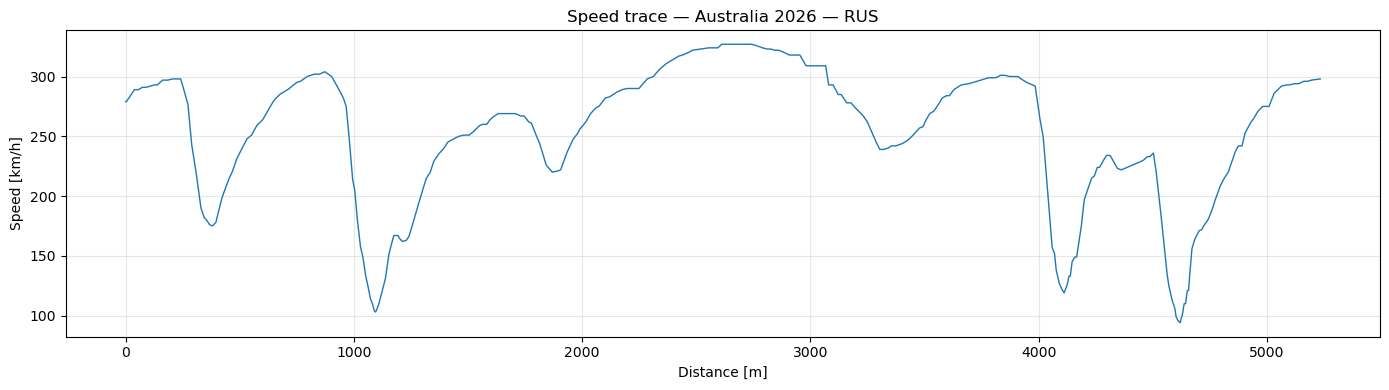

In [6]:
tel = aus['pole_tel']
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(tel['Distance'], tel['Speed'], lw=1)
ax.set_xlabel('Distance [m]')
ax.set_ylabel('Speed [km/h]')
ax.set_title(f"Speed trace — Australia 2026 — {pole['Driver']}")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

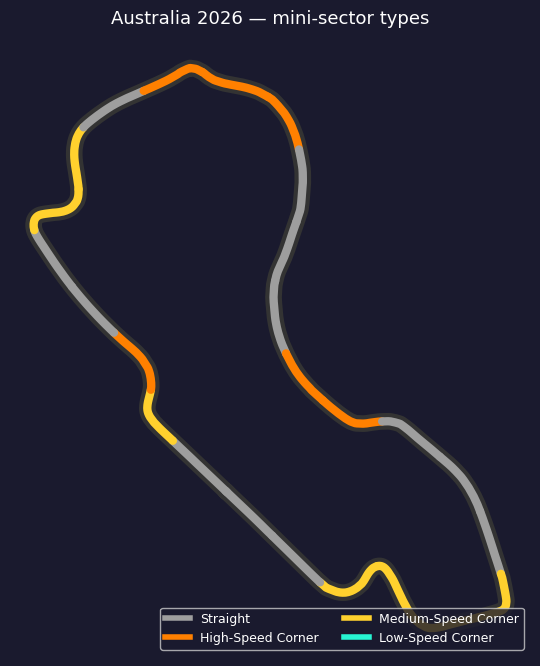

In [7]:
fig, ax = draw_track(aus, aus['sectors']['type'].map(TYPE_COLORS).to_dict(), 'Australia 2026 — mini-sector types')
add_legend(ax, TYPE_COLORS)
plt.show()

## 5. Driver ratings

Ratings are averaged over the four circuits. When each circuit loads, it prints the pole lap as a percentage of the ideal lap. That should be just above 100 %, because the ideal lap combines everyone's best mini-sectors.

China: pole 92.064 s, ideal lap 88.754 s (103.7 % of ideal)
Japan: pole 88.778 s, ideal lap 86.225 s (103.0 % of ideal)


_api        WARNING 	Driver 81: Encountered 1 timing integrity error(s) near lap(s): [3].
This might be a bug and should be reported.


Miami: pole 87.798 s, ideal lap 84.714 s (103.6 % of ideal)


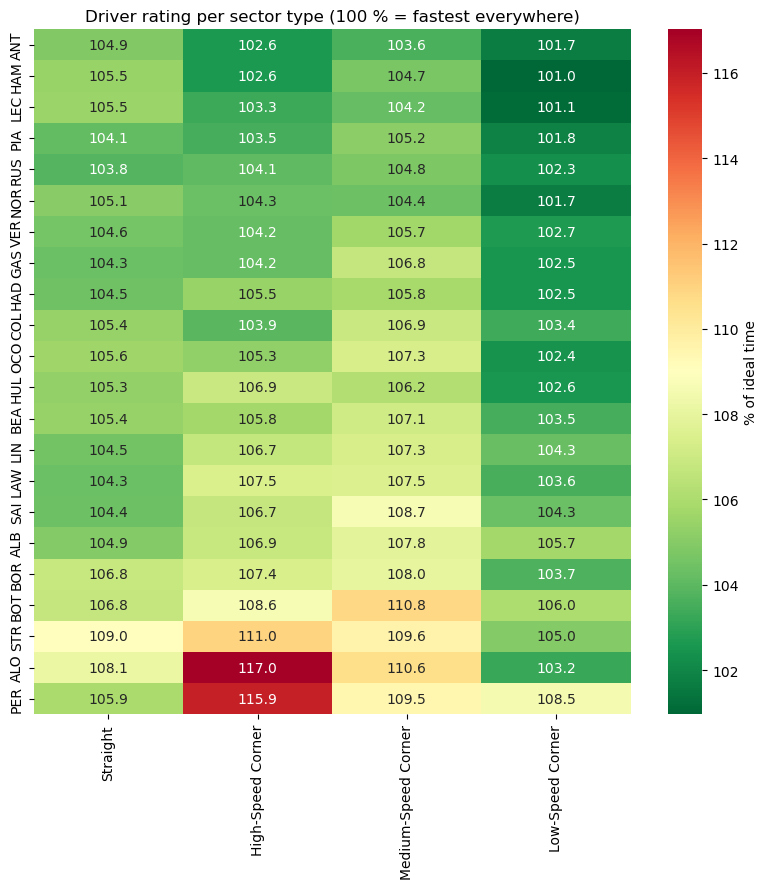

In [8]:
for gp in TRAIN_CIRCUITS[1:]:
    circuits[gp] = load_circuit(2026, gp)

ratings = pd.concat({gp: driver_ratings(c['times']) for gp, c in circuits.items()}, names=['circuit'])


def driver_profile(ratings):
    # Average rating per sector type. Gaps are filled with the field average for that type,
    # or with the overall average if no training circuit has that type at all.
    prof = ratings.reindex(columns=SECTOR_TYPES).groupby('driver').mean()
    return prof.fillna(prof.mean()).fillna(prof.stack().mean())


profile = driver_profile(ratings)
profile = profile.loc[profile.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(profile, annot=True, fmt='.1f', cmap='RdYlGn_r', cbar_kws={'label': '% of ideal time'}, ax=ax)
ax.set_title('Driver rating per sector type (100 % = fastest everywhere)')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## 6. Circuit profiles

The circuits to predict are described by their 2025 pole laps, since 2026 data for them wasn't available when I built this. The four training circuits use their 2026 profiles.

In [9]:
PREDICT_CIRCUITS = [
    'Bahrain', 'Saudi Arabia', 'Monaco', 'Spain', 'Canada', 'Austria', 'Britain', 'Hungary', 'Belgium',
    'Netherlands', 'Italy', 'Azerbaijan', 'Singapore', 'United States', 'Mexico', 'Brazil', 'Las Vegas', 'Abu Dhabi',
]

profiles = {gp: c['profile'] for gp, c in circuits.items()}
for gp in PREDICT_CIRCUITS:
    try:
        profiles[gp] = load_circuit(2025, gp, with_drivers=False)['profile']
    except Exception as e:
        print(f'  {gp} skipped: {e}')

circuit_profiles = pd.DataFrame(profiles).T
(circuit_profiles * 100).round(1).sort_values('Straight', ascending=False)

_api        WARNING 	Driver  2: Car data is incomplete!
_api        WARNING 	Driver  3: Car data is incomplete!
_api        WARNING 	Driver  8: Car data is incomplete!
_api        WARNING 	Driver  9: Car data is incomplete!
_api        WARNING 	Driver 11: Car data is incomplete!
_api        WARNING 	Driver 15: Car data is incomplete!
_api        WARNING 	Driver 17: Car data is incomplete!
_api        WARNING 	Driver 19: Car data is incomplete!
_api        WARNING 	Driver 20: Car data is incomplete!
_api        WARNING 	Driver 21: Car data is incomplete!
_api        WARNING 	Driver 24: Car data is incomplete!
_api        WARNING 	Driver 25: Car data is incomplete!
_api        WARNING 	Driver 26: Car data is incomplete!
_api        WARNING 	Driver 28: Car data is incomplete!
_api        WARNING 	Driver 29: Car data is incomplete!
_api        WARNING 	Driver 44: Car data is incomplete!
_api        WARNING 	Driver 55: Car data is incomplete!
_api        WARNING 	Driver 63: Car data is inco

type,Straight,High-Speed Corner,Medium-Speed Corner,Low-Speed Corner
Italy,55.2,7.1,30.1,7.6
Abu Dhabi,51.3,11.0,30.2,7.5
Canada,51.0,0.0,33.7,15.3
Saudi Arabia,48.1,15.8,36.1,0.0
Las Vegas,46.9,0.0,24.8,28.3
Azerbaijan,45.2,0.0,48.6,6.3
Monaco,45.1,3.0,24.5,27.4
Miami,43.9,3.4,23.5,29.2
Austria,43.8,23.2,33.0,0.0
Belgium,43.4,13.8,35.1,7.7


## 7. Predicting pace on a new circuit

**Features.** For each sector type: *driver rating × share of the lap the circuit spends in that type*. If all model weights were 1, the sum would be exactly the driver's expected lap rating on that circuit. Ridge regression learns how much each type actually matters.

The features have to combine driver and circuit. With driver and circuit features side by side in a linear model, the circuit part adds the same amount to every driver, so the predicted ranking would be identical on every track.

**Target.** The driver's whole-lap rating at that circuit.

**Evaluation.** Leave-one-circuit-out: train on three circuits, predict the fourth. The driver profiles are rebuilt from the three training circuits only, so no information from the test circuit leaks in. The model is compared with a baseline that ignores the circuit: each driver's average lap rating on the training circuits. Spearman ρ measures how well the predicted *order* matches the real one.

In [10]:
def make_features(profile, circuit_profile):
    return profile[SECTOR_TYPES] * circuit_profile[SECTOR_TYPES].to_numpy()


def build_dataset(ratings, profile, gps):
    parts = []
    for gp in gps:
        X = make_features(profile, circuit_profiles.loc[gp])
        y = ratings.loc[gp, 'Lap'].rename('target')
        parts.append(X.join(y, how='inner').assign(circuit=gp))
    return pd.concat(parts)


def make_model():
    return make_pipeline(StandardScaler(), Ridge(alpha=1.0))


results = []
for test_gp in TRAIN_CIRCUITS:
    train_gps = [gp for gp in TRAIN_CIRCUITS if gp != test_gp]
    prof = driver_profile(ratings.loc[train_gps])          # built without the test circuit
    train = build_dataset(ratings, prof, train_gps)
    test = build_dataset(ratings, prof, [test_gp])

    model = make_model().fit(train[SECTOR_TYPES], train['target'])
    pred = model.predict(test[SECTOR_TYPES])
    baseline = ratings.loc[train_gps, 'Lap'].groupby('driver').mean().reindex(test.index)

    results.append({
        'circuit': test_gp,
        'MAE model (%)': mean_absolute_error(test['target'], pred),
        'Spearman model': spearmanr(test['target'], pred)[0],
        'Spearman baseline': spearmanr(test['target'], baseline, nan_policy='omit')[0],
    })

pd.DataFrame(results).set_index('circuit').round(3)

,MAE model (%),Spearman model,Spearman baseline
circuit,,,
Australia,1.509,0.691,0.779
China,1.801,0.744,0.899
Japan,1.523,0.792,0.842
Miami,3.953,0.555,0.799


### Prediction for Monaco

The final model is trained on all four circuits.

In [11]:
full = build_dataset(ratings, profile, TRAIN_CIRCUITS)
model = make_model().fit(full[SECTOR_TYPES], full['target'])


def predict_ranking(gp):
    pred = pd.Series(model.predict(make_features(profile, circuit_profiles.loc[gp])),
                     index=profile.index, name='predicted_lap_%').sort_values()
    return pred.to_frame().assign(rank=range(1, len(pred) + 1)).round(2)


predict_ranking('Monaco')

,predicted_lap_%,rank
driver,,
RUS,106.02,1
PIA,106.19,2
ANT,106.45,3
HAD,106.53,4
GAS,106.53,5
VER,106.59,6
NOR,106.67,7
LAW,106.71,8
LEC,106.83,9


## 8. Mini-sectors on the track

### Fastest driver in each mini-sector

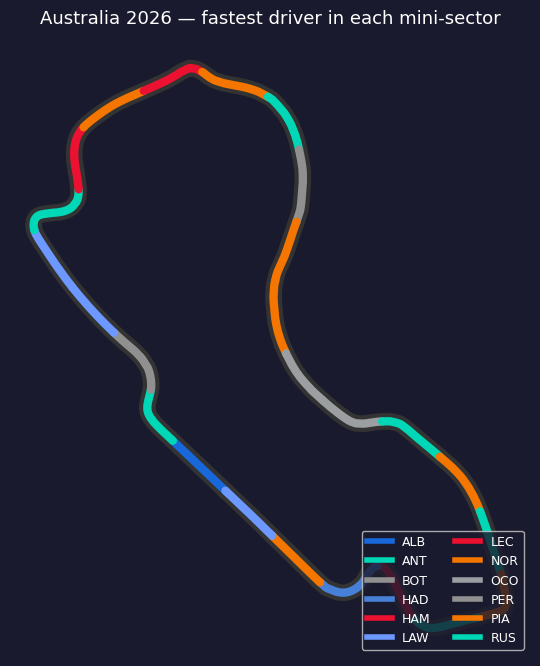

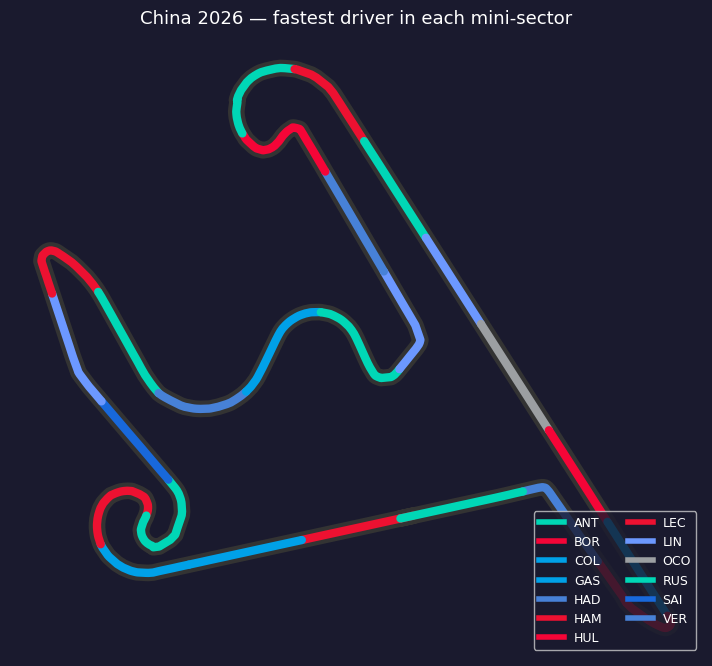

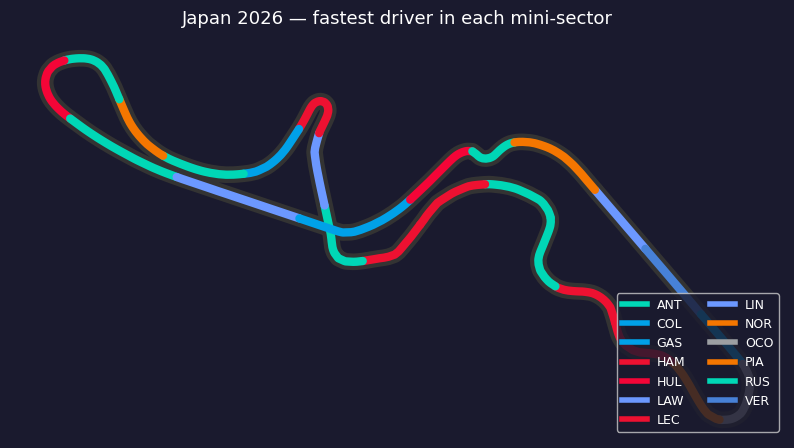

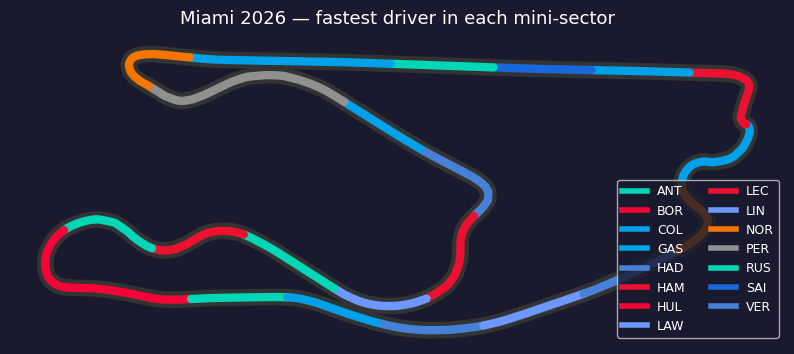

In [12]:
def plot_fastest_per_sector(gp):
    c = circuits[gp]
    t = c['times']
    fastest = t.loc[t.groupby('sector_id')['sector_time'].idxmin()].set_index('sector_id')['driver']
    colors = {d: driver_color(d, c['session']) for d in sorted(fastest.unique())}
    fig, ax = draw_track(c, {s: colors[d] for s, d in fastest.items()},
                         f'{gp} 2026 — fastest driver in each mini-sector')
    add_legend(ax, colors)
    plt.show()


for gp in TRAIN_CIRCUITS:
    plot_fastest_per_sector(gp)

### Head to head

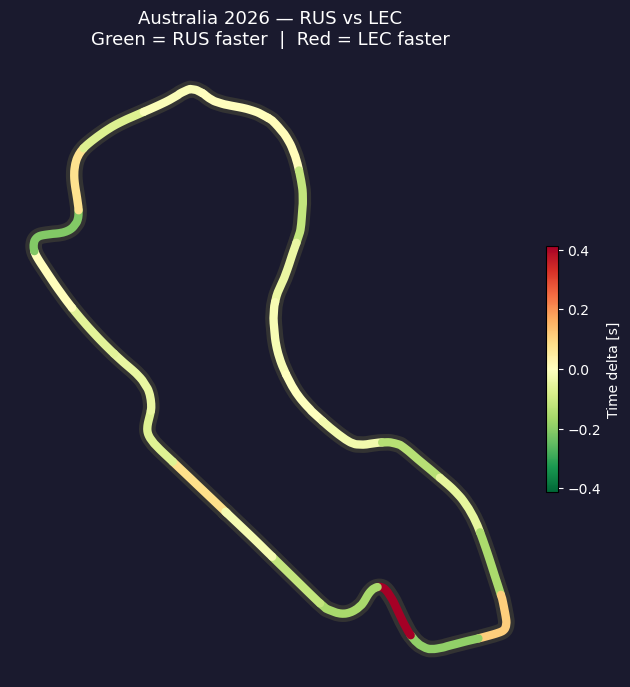

In [13]:
def plot_head_to_head(gp, a, b):
    c = circuits[gp]
    t = c['times'].pivot(index='sector_id', columns='driver', values='sector_time')
    delta = (t[a] - t[b]).dropna()                 # negative = a is faster
    lim = delta.abs().max()
    norm = mcolors.TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    cmap = plt.cm.RdYlGn_r

    fig, ax = draw_track(c, {s: cmap(norm(d)) for s, d in delta.items()},
                         f'{gp} 2026 — {a} vs {b}\nGreen = {a} faster  |  Red = {b} faster')
    cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.4, pad=0.02)
    cbar.set_label('Time delta [s]', color='white')
    cbar.ax.yaxis.set_tick_params(color='white')
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color='white')
    plt.show()


plot_head_to_head('Australia', 'RUS', 'LEC')

## Limitations

- **One lap per driver per circuit.** Drivers knocked out in Q1 set their best lap on a less rubbered-in track than those in Q3, which makes them look slower than they are.
- **Four circuits** are not much data to learn from, so the evaluation numbers are noisy.
- **Hand-picked thresholds.** The sector-type thresholds (curvature 15 %, speed 70 % / 40 %) are my own choice.
- **2025 profiles** describe the prediction circuits, while the 2026 cars have a different speed profile.